# Quantiles and GBC: a reference for final projects

This notebook is ungraded. It is a reference you can read alone and copy code from. It has no exercises and no solutions file.

Every number in the text was produced by the cells below when this notebook was built. Data marked *simulated* were generated by the code. Numbers marked *made-up* were chosen by the author to make an example concrete. Neither is real.

Each section ends with a short **Try it on your project** note.

## Which tool for which problem

Start from the table. Find the row that looks like your data, then read the section named in the last column.

| Problem type | Example | Tool | Section |
|---|---|---|---|
| Lots of data and a percentile target | trip durations, hourly demand | quantile boosting, or an implicit quantile network (IQN) | 4, 6 |
| A few thousand rows and a tilted cost | auction prices | linear quantile regression on the log of the target, then boosting | 3, 4 |
| A few hundred rows | weekly returns | linear quantile regression only, because there are too few rows for a network | 3 |
| Extreme highs | peak demand | quantile regression for the body, plus a generalized Pareto tail | 5 |
| A simulator is available and a posterior is wanted | a model you can simulate but cannot write a likelihood for | Generative Bayesian Computation (GBC) | 7 |

Three ideas run through the whole notebook.

- A **quantile** is a cut point. The 0.8 quantile of demand is the value that demand stays below 80% of the time.
- The **pinball loss** scores a quantile forecast. It is the loss that every method below minimizes.
- A decision with unequal costs for being too low and too high needs exactly one quantile. It does not need the whole distribution and it does not need the mean.


In [1]:
import random
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

try:
    import gbc
except ImportError:  # Colab or a fresh environment: install the package once
    %pip install -q "git+https://github.com/VadimSokolov/gbc.git@v0.7.2"
    import gbc
from gbc import predict_iqn, sample_iqn, train_iqn
from gbc.metrics import coverage, pit_values

T_START = perf_counter()
SEED = 600
random.seed(SEED)
np.random.seed(SEED)

DATA = Path("data")
DATA.mkdir(exist_ok=True)
BASE = "https://vsokolov.org/courses/files/600/data"
for name in ("diamonds.csv",):
    path = DATA / name
    if not path.exists():
        urlretrieve(f"{BASE}/{name}", path)

plt.rcParams["figure.figsize"] = (6, 3.8)
plt.rcParams["figure.dpi"] = 90
print("gbc version:", gbc.__version__)


/Users/vsokolov/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gbc version: 0.7.2


## 1. The newsvendor: a cost gives you a quantile

A vendor must order $q$ units before demand $D$ is known.

- If the order is too small, each unit of unmet demand costs $c_\text{under}$.
- If the order is too large, each unsold unit costs $c_\text{over}$.

The cost of one outcome is

$$\text{cost}(q, D) = c_\text{under}\,\max(D - q, 0) + c_\text{over}\,\max(q - D, 0).$$

The expected cost is minimized by ordering the $\tau$ quantile of demand, where

$$\tau = \frac{c_\text{under}}{c_\text{under} + c_\text{over}}.$$

Here $\tau$ is a probability between 0 and 1. A large $c_\text{under}$ pushes $\tau$ toward 1, so you order a high quantile.

The next cell checks this by simulation. The demand is *simulated*: a lognormal distribution whose parameters were made up. The costs are *made-up* too: $c_\text{under} = 4$ and $c_\text{over} = 1$, so $\tau = 0.8$. The cell computes the expected cost on a grid of orders and finds the minimum.


tau = c_under / (c_under + c_over) = 0.80
order at the minimum expected cost on the grid : 137
sample 0.80 quantile of demand               : 137.2
true 0.80 quantile of the simulated law      : 137.1
expected cost, order = tau quantile : 84.73
expected cost, order = mean demand  : 100.58  (mean = 102.0)
expected cost, order = median demand: 115.57  (median = 89.9)


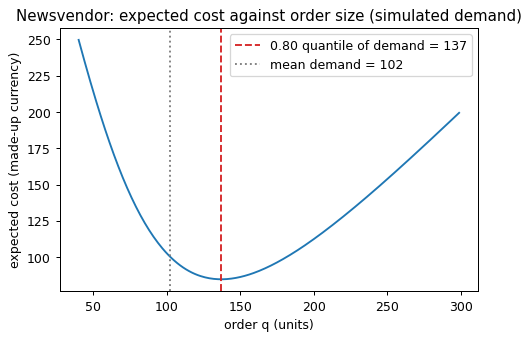

In [2]:
c_under, c_over = 4.0, 1.0
tau_cost = c_under / (c_under + c_over)

rng = np.random.default_rng(SEED)
demand = rng.lognormal(mean=4.5, sigma=0.5, size=200_000)  # simulated demand

def cost(q, d):
    return c_under * np.maximum(d - q, 0) + c_over * np.maximum(q - d, 0)

orders = np.arange(40.0, 300.0, 1.0)
exp_cost = np.array([cost(q, demand).mean() for q in orders])

best_order = orders[exp_cost.argmin()]
sample_q = np.quantile(demand, tau_cost)
true_q = np.exp(4.5 + 0.5 * stats.norm.ppf(tau_cost))
cost_best = exp_cost.min()
cost_mean = cost(demand.mean(), demand).mean()
cost_median = cost(np.median(demand), demand).mean()

print(f"tau = c_under / (c_under + c_over) = {tau_cost:.2f}")
print(f"order at the minimum expected cost on the grid : {best_order:.0f}")
print(f"sample {tau_cost:.2f} quantile of demand               : {sample_q:.1f}")
print(f"true {tau_cost:.2f} quantile of the simulated law      : {true_q:.1f}")
print(f"expected cost, order = tau quantile : {cost_best:.2f}")
print(f"expected cost, order = mean demand  : {cost_mean:.2f}  (mean = {demand.mean():.1f})")
print(f"expected cost, order = median demand: {cost_median:.2f}  (median = {np.median(demand):.1f})")

fig, ax = plt.subplots()
ax.plot(orders, exp_cost, color="#1f77b4")
ax.axvline(sample_q, color="#d62728", ls="--", label=f"{tau_cost:.2f} quantile of demand = {sample_q:.0f}")
ax.axvline(demand.mean(), color="#7f7f7f", ls=":", label=f"mean demand = {demand.mean():.0f}")
ax.set_xlabel("order q (units)")
ax.set_ylabel("expected cost (made-up currency)")
ax.set_title("Newsvendor: expected cost against order size (simulated demand)")
ax.legend()
plt.show()


The expected cost is lowest when the order sits at the $\tau = 0.8$ quantile of demand, about 137 units on the grid. The sample quantile is 137.2 and the exact quantile of the simulated law is 137.1. The grid has step 1, so it agrees with the sample quantile up to that step.

Ordering the mean demand (102.0 units) costs 100.58 per period. Ordering the 0.8 quantile costs 84.73. The mean is the wrong target here because the two errors are not priced equally.

**Try it on your project.** Write down the cost of forecasting too low and the cost of forecasting too high. Compute $\tau = c_\text{under} / (c_\text{under} + c_\text{over})$. That $\tau$ is the quantile your model must predict.


## 2. Pinball loss: the score that matches the decision

Let $y$ be the observed value and $q$ a quantile forecast. Define the error $u = y - q$. The **pinball loss** at level $\tau$ is

$$\rho_\tau(u) = u\,\big(\tau - \mathbf{1}[u < 0]\big).$$

Here $\mathbf{1}[u < 0]$ equals 1 when $u < 0$ and 0 otherwise. In words:

- If $y$ is above the forecast ($u > 0$), the loss is $\tau\,u$.
- If $y$ is below the forecast ($u < 0$), the loss is $(1 - \tau)\,|u|$.

The two slopes differ. A high $\tau$ punishes forecasts that are too low more than forecasts that are too high.


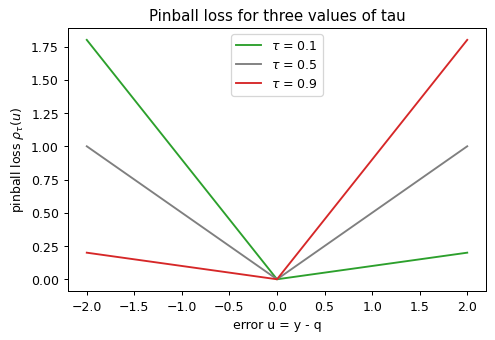

In [3]:
def rho(u, tau):
    return u * (tau - (u < 0))

u_grid = np.linspace(-2, 2, 401)
fig, ax = plt.subplots()
for tau, color in [(0.1, "#2ca02c"), (0.5, "#7f7f7f"), (0.9, "#d62728")]:
    ax.plot(u_grid, rho(u_grid, tau), label=rf"$\tau$ = {tau}", color=color)
ax.set_xlabel("error u = y - q")
ax.set_ylabel(r"pinball loss $\rho_\tau(u)$")
ax.set_title("Pinball loss for three values of tau")
ax.legend()
plt.show()


**The average pinball loss is smallest at the sample quantile.** The next cell takes 5,000 of the simulated demands from Section 1. It scores every forecast $q$ on a grid with the average pinball loss at $\tau = 0.8$ and reports which $q$ wins.


grid minimizer of average pinball loss at tau = 0.8: 133.80
sample quantile of the same 5,000 values            : 133.82


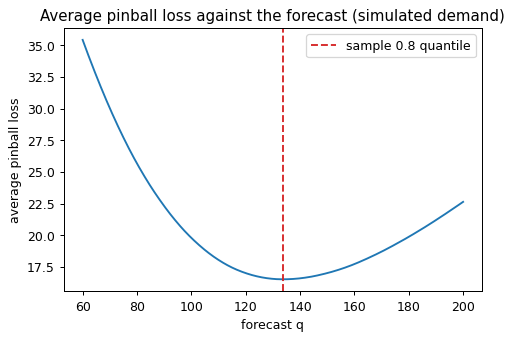

In [4]:
y5 = demand[:5000]
q_grid = np.linspace(60, 200, 1401)
avg_pin = np.array([rho(y5 - q, tau_cost).mean() for q in q_grid])
argmin_pin = q_grid[avg_pin.argmin()]
sample_q5 = np.quantile(y5, tau_cost)
print(f"grid minimizer of average pinball loss at tau = {tau_cost}: {argmin_pin:.2f}")
print(f"sample quantile of the same 5,000 values            : {sample_q5:.2f}")

fig, ax = plt.subplots()
ax.plot(q_grid, avg_pin, color="#1f77b4")
ax.axvline(sample_q5, color="#d62728", ls="--", label="sample 0.8 quantile")
ax.set_xlabel("forecast q")
ax.set_ylabel("average pinball loss")
ax.set_title("Average pinball loss against the forecast (simulated demand)")
ax.legend()
plt.show()


The grid minimizer is 133.80 and the sample quantile is 133.82. They agree up to the grid step of 0.1.

**Pinball loss is the decision's expected cost, up to a scale.** Take the newsvendor cost from Section 1 with $\tau = c_\text{under} / (c_\text{under} + c_\text{over})$. Then

$$\text{cost}(q, D) = (c_\text{under} + c_\text{over})\;\rho_\tau(D - q).$$

When demand exceeds the order ($u > 0$), the pinball loss is $\tau\,u$ and the factor $(c_\text{under} + c_\text{over})\,\tau$ equals $c_\text{under}$. When demand falls short ($u < 0$), the factor $(c_\text{under} + c_\text{over})(1 - \tau)$ equals $c_\text{over}$. So the average pinball loss at the cost-implied $\tau$ is the expected cost divided by $c_\text{under} + c_\text{over}$.

This is why pinball loss at that $\tau$ is the right score for a project. A model with a lower held-out pinball loss would have a lower expected cost if you used it to make the decision. The next cell confirms the identity numerically.


In [5]:
pin_cost = (c_under + c_over) * np.array([rho(demand - q, tau_cost).mean() for q in orders])
max_identity_gap = np.abs(pin_cost - exp_cost).max()
print(f"largest gap between (c_under + c_over) * average pinball loss and expected cost: {max_identity_gap:.2e}")

# MAE is the tau = 0.5 case: rho_0.5(u) = |u| / 2
mae_half_gap = np.abs(rho(y5 - 120.0, 0.5).mean() - 0.5 * np.abs(y5 - 120.0).mean())
mae_grid = np.array([np.abs(y5 - q).mean() for q in q_grid])
print(f"|average pinball at tau = 0.5  minus  MAE / 2| at q = 120: {mae_half_gap:.2e}")
print(f"grid minimizer of MAE: {q_grid[mae_grid.argmin()]:.2f}   sample median: {np.median(y5):.2f}")


largest gap between (c_under + c_over) * average pinball loss and expected cost: 8.53e-14
|average pinball at tau = 0.5  minus  MAE / 2| at q = 120: 0.00e+00
grid minimizer of MAE: 89.00   sample median: 89.04


The gap between the two sides of the identity is at most 8.5e-14, which is rounding error. The identity holds.

**Mean absolute error (MAE) is the $\tau = 0.5$ case.** At $\tau = 0.5$ both slopes of the pinball loss equal 0.5, so $\rho_{0.5}(u) = |u|/2$. The average pinball loss at $\tau = 0.5$ is half the MAE. The minimizer of MAE is therefore the median, 89.00 on the grid against a sample median of 89.04. A model scored by MAE is a model for the median. It says nothing about the 0.9 quantile.

**Do not compare pinball losses across different $\tau$.** The scale changes with $\tau$. Compare models at the same $\tau$.

**Try it on your project.** Write the score function as the average pinball loss at your $\tau$. Compute it on held-out data only. Report it next to the same score for a baseline that ignores the features (Section 4 shows one).


## 3. Linear quantile regression

Linear quantile regression fits a line for one quantile. For level $\tau$ it chooses coefficients $\beta_\tau$ that minimize the average pinball loss of the forecast $x^\top \beta_\tau$. You fit one line per $\tau$.

The data are the course `diamonds.csv`: 5,000 diamonds with `price` in dollars and `carat` weight, plus cut, color, clarity, and measurements. Prices are right-skewed and the spread grows with size, so the model works on logs: $\log(\text{price})$ against $\log(\text{carat})$.


        count     mean     min       max
carat  5000.0     0.80    0.20      4.50
price  5000.0  3942.83  326.00  18818.00
lc     5000.0    -0.39   -1.61      1.50
lp     5000.0     7.79    5.79      9.84

tau   intercept   slope on log carat
0.1       8.131   1.685
0.5       8.436   1.641
0.9       8.800   1.719
OLS       8.445   1.667

fitted price of a 1 carat stone: {0.1: 3399, 0.5: 4611, 0.9: 6634}
0.9 line over 0.5 line at 1 carat: 1.439
the 0.1 and 0.9 lines cross at 3.97e-09 carat (data range: 0.2 to 4.5)


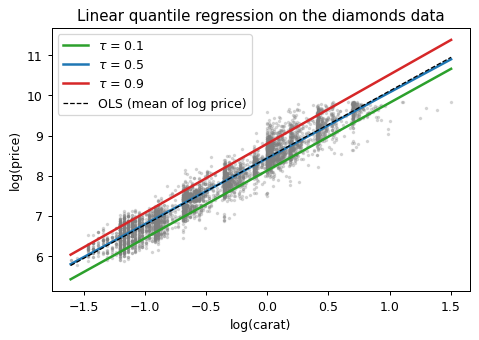

In [6]:
import statsmodels.api as sm

dia = pd.read_csv(DATA / "diamonds.csv")
dia["lp"] = np.log(dia["price"])
dia["lc"] = np.log(dia["carat"])
print(dia[["carat", "price", "lc", "lp"]].describe().round(2).T[["count", "mean", "min", "max"]])

X1 = sm.add_constant(dia[["lc"]])
qr = {t: sm.QuantReg(dia["lp"], X1).fit(q=t, max_iter=5000) for t in (0.1, 0.5, 0.9)}
ols = sm.OLS(dia["lp"], X1).fit()

slopes = {t: qr[t].params["lc"] for t in qr}
icepts = {t: qr[t].params["const"] for t in qr}
print()
print("tau   intercept   slope on log carat")
for t in qr:
    print(f"{t:.1f}   {icepts[t]:9.3f}   {slopes[t]:.3f}")
print(f"OLS   {ols.params['const']:9.3f}   {ols.params['lc']:.3f}")

price_at_1 = {t: float(np.exp(icepts[t])) for t in qr}          # log carat = 0 is one carat
ratio_90_50 = price_at_1[0.9] / price_at_1[0.5]
print()
print("fitted price of a 1 carat stone:", {t: round(p) for t, p in price_at_1.items()})
print(f"0.9 line over 0.5 line at 1 carat: {ratio_90_50:.3f}")

# where would the 0.1 and 0.9 lines cross?
x_cross = (icepts[0.1] - icepts[0.9]) / (slopes[0.9] - slopes[0.1])
carat_cross = float(np.exp(x_cross))
print(f"the 0.1 and 0.9 lines cross at {carat_cross:.3g} carat (data range: {dia['carat'].min()} to {dia['carat'].max()})")

xs = np.linspace(dia["lc"].min(), dia["lc"].max(), 100)
fig, ax = plt.subplots()
ax.scatter(dia["lc"], dia["lp"], s=3, alpha=0.25, color="#7f7f7f")
for t, color in [(0.1, "#2ca02c"), (0.5, "#1f77b4"), (0.9, "#d62728")]:
    ax.plot(xs, icepts[t] + slopes[t] * xs, color=color, lw=2, label=rf"$\tau$ = {t}")
ax.plot(xs, ols.params["const"] + ols.params["lc"] * xs, color="black", ls="--", lw=1, label="OLS (mean of log price)")
ax.set_xlabel("log(carat)")
ax.set_ylabel("log(price)")
ax.set_title("Linear quantile regression on the diamonds data")
ax.legend()
plt.show()


**How the slope changes with $\tau$.** The slope on $\log(\text{carat})$ is 1.685 at $\tau = 0.1$, 1.641 at $\tau = 0.5$ and 1.719 at $\tau = 0.9$. The ordinary least squares (OLS) slope, which targets the mean of log price, is 1.667. A slope is an elasticity here: a 1% larger stone is about that many percent more expensive. If the slopes differ across $\tau$, the spread of prices changes with size. Equal slopes would mean the spread is the same for small and large stones. The three slopes here span only 0.079, so the spread of log price is close to constant across stone sizes. The lines are almost parallel and the gap between them comes mostly from the intercepts.

**A list price is a high quantile of sales.** At 1 carat the fitted 0.9 line is 1.44 times the fitted 0.5 line. A price that is posted for a good stone sits near the top of what similar stones sell for. It is not the mean of sales and it is not the median. If you model posted prices or reserve prices, use the quantile that matches how the price was set.

**Crossing.** Quantiles must be ordered: the 0.9 forecast must be at least the 0.1 forecast for the same input. Separate lines have no such guarantee. If two lines have different slopes, they cross somewhere. Here the 0.1 and 0.9 lines would cross at about 3.97e-09 carat, which is far below the data range of 0.20 to 4.50 carat, so one predictor causes no trouble in the data. With several predictors and many $\tau$ levels, crossing appears. The next cell fits 19 levels on three predictors (log carat, depth, table) and counts crossings, first on the diamonds in the data and then on a wider grid of inputs that extends beyond them.


In [7]:
taus_19 = np.round(np.arange(0.05, 0.951, 0.05), 2)
feats3 = ["lc", "depth", "table"]
X3 = sm.add_constant(dia[feats3])
fits19 = {t: sm.QuantReg(dia["lp"], X3).fit(q=t, max_iter=5000) for t in taus_19}

def predict19(df):
    Xn = sm.add_constant(df[feats3], has_constant="add")
    return np.column_stack([fits19[t].predict(Xn) for t in taus_19])   # rows x levels

def crossing_rows(P):
    return float((np.diff(P, axis=1) < 0).any(axis=1).mean())

P_data = predict19(dia)
wide = pd.DataFrame(
    [(np.log(c), d, tb) for c in (0.2, 0.5, 1, 2, 4, 5) for d in (50, 56, 62, 68, 75) for tb in (45, 55, 65, 75)],
    columns=feats3,
)
P_wide = predict19(wide)

cross_data = crossing_rows(P_data)
cross_wide = crossing_rows(P_wide)
print(f"share of the 5,000 diamonds with at least one crossing   : {cross_data:.3f}")
print(f"share of {len(wide)} wide-grid inputs with at least one crossing: {cross_wide:.3f}")

# repair: sort the predictions across tau, row by row
P_wide_sorted = np.sort(P_wide, axis=1)
print(f"share with a crossing after sorting                     : {crossing_rows(P_wide_sorted):.3f}")

# sorting cannot raise the average pinball loss; check on the data rows
def avg_pin_levels(P, y):
    return float(np.mean([rho(y - P[:, k], t).mean() for k, t in enumerate(taus_19)]))

pin_raw = avg_pin_levels(P_data, dia["lp"].to_numpy())
pin_sorted = avg_pin_levels(np.sort(P_data, axis=1), dia["lp"].to_numpy())
print(f"average pinball loss over the 19 levels on the data, raw   : {pin_raw:.5f}")
print(f"average pinball loss over the 19 levels on the data, sorted: {pin_sorted:.5f}")


share of the 5,000 diamonds with at least one crossing   : 0.001
share of 120 wide-grid inputs with at least one crossing: 0.575
share with a crossing after sorting                     : 0.000
average pinball loss over the 19 levels on the data, raw   : 0.07494
average pinball loss over the 19 levels on the data, sorted: 0.07494


On the diamonds themselves the share of inputs with a crossing is 0.001. On the wider grid, which includes stones much larger and smaller than the data, the share is 0.575. Crossing shows up when you leave the region where the data are dense.

**The repair is to sort.** For each input, sort the predicted quantiles from lowest to highest across $\tau$. After sorting, the share with a crossing is 0.000 by construction. Sorting never raises the pinball loss. On the data the average over the 19 levels is 0.0749 before and 0.0749 after. This is called rearrangement. In code it is one line: `np.sort(P, axis=1)`.

**Try it on your project.** Fit your target at three levels, for example 0.1, 0.5 and 0.9. Plot the three fits against your main predictor. Check that the upper line stays above the lower line. If you predict many levels, sort across $\tau$ before you report them.


## 4. Quantile boosting

Gradient boosting builds many small trees, each correcting the errors of the sum so far. With `loss="quantile"` the errors are measured by the pinball loss, so the model predicts a quantile instead of the mean. It can pick up curves and interactions that a straight line misses. You fit one model per $\tau$.

The test below uses the diamonds again, with log price as the target. The predictors are carat, depth, table, and the three grade columns coded as ordered integers. The score is the pinball loss on 1,000 held-out rows that the models never saw. Three predictors are compared:

- **Baseline:** the unconditional quantile of the training prices. It ignores the features.
- **Linear quantile regression:** the model of Section 3 with more predictors.
- **Boosting:** `GradientBoostingRegressor(loss="quantile", alpha=tau)`.

A quantile model should also be **calibrated**: a forecast at level $\tau$ should be above the outcome about a share $\tau$ of the time. The cell reports this share and the coverage of the 80% band between the 0.1 and 0.9 forecasts.


In [8]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split

cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order = ["J", "I", "H", "G", "F", "E", "D"]
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
d4 = dia.copy()
d4["cut_i"] = d4["cut"].map({v: i for i, v in enumerate(cut_order)})
d4["color_i"] = d4["color"].map({v: i for i, v in enumerate(color_order)})
d4["clarity_i"] = d4["clarity"].map({v: i for i, v in enumerate(clarity_order)})

feats_gb = ["carat", "depth", "table", "cut_i", "color_i", "clarity_i"]
feats_lin = ["lc", "depth", "table", "cut_i", "color_i", "clarity_i"]
tr, te = train_test_split(d4, test_size=0.2, random_state=SEED)   # random split: rows are not time-ordered
ytr, yte = tr["lp"].to_numpy(), te["lp"].to_numpy()

taus4 = (0.1, 0.5, 0.9)
pred_base, pred_lin, pred_gb = {}, {}, {}
t0 = perf_counter()
for t in taus4:
    pred_base[t] = np.full(len(te), np.quantile(ytr, t))
    Xl_tr = sm.add_constant(tr[feats_lin])
    pred_lin[t] = sm.QuantReg(ytr, Xl_tr).fit(q=t, max_iter=5000).predict(sm.add_constant(te[feats_lin], has_constant="add")).to_numpy()
    gb = GradientBoostingRegressor(loss="quantile", alpha=t, n_estimators=300, learning_rate=0.05,
                                   max_depth=3, min_samples_leaf=20, random_state=SEED)
    gb.fit(tr[feats_gb], ytr)
    pred_gb[t] = gb.predict(te[feats_gb])
time_boost = perf_counter() - t0

rows = []
for t in taus4:
    rows.append({
        "tau": t,
        "baseline": rho(yte - pred_base[t], t).mean(),
        "linear QR": rho(yte - pred_lin[t], t).mean(),
        "boosting": rho(yte - pred_gb[t], t).mean(),
        "share y below, linear": (yte < pred_lin[t]).mean(),
        "share y below, boosting": (yte < pred_gb[t]).mean(),
    })
tab4 = pd.DataFrame(rows).set_index("tau")
print(f"held-out rows: {len(te)}   fit time for all models: {time_boost:.1f} s")
print(tab4.round(4).to_string())

band = {}
for name, P in [("baseline", pred_base), ("linear QR", pred_lin), ("boosting", pred_gb)]:
    band[name] = float(np.mean((yte >= P[0.1]) & (yte <= P[0.9])))
print("coverage of the 80% band [q0.1, q0.9] on held-out rows:", {k: round(v, 3) for k, v in band.items()})
gain_gb_vs_lin = {t: 1 - tab4.loc[t, "boosting"] / tab4.loc[t, "linear QR"] for t in taus4}
gain_lin_vs_base = {t: 1 - tab4.loc[t, "linear QR"] / tab4.loc[t, "baseline"] for t in taus4}
print("pinball reduction, linear QR vs baseline:", {t: round(v, 3) for t, v in gain_lin_vs_base.items()})
print("pinball reduction, boosting vs linear QR:", {t: round(v, 3) for t, v in gain_gb_vs_lin.items()})


held-out rows: 1000   fit time for all models: 2.6 s
     baseline  linear QR  boosting  share y below, linear  share y below, boosting
tau                                                                               
0.1    0.1516     0.0279    0.0194                  0.117                    0.116
0.5    0.4449     0.0558    0.0406                  0.482                    0.499
0.9    0.1726     0.0237    0.0193                  0.908                    0.909
coverage of the 80% band [q0.1, q0.9] on held-out rows: {'baseline': 0.782, 'linear QR': 0.791, 'boosting': 0.793}
pinball reduction, linear QR vs baseline: {0.1: np.float64(0.816), 0.5: np.float64(0.874), 0.9: np.float64(0.863)}
pinball reduction, boosting vs linear QR: {0.1: np.float64(0.306), 0.5: np.float64(0.272), 0.9: np.float64(0.185)}


Read the table row by row. Lower pinball loss is better.

- **Linear quantile regression against the baseline.** Pinball loss falls by 82% at $\tau = 0.1$, 87% at $\tau = 0.5$ and 86% at $\tau = 0.9$. The features carry most of the information.
- **Boosting against linear quantile regression.** Pinball loss falls by a further 31%, 27% and 18%. Boosting learns the curvature in the carat effect and the grade effects that the straight line misses.
- **Calibration.** The share of held-out outcomes below the boosting forecast is 0.116, 0.499 and 0.909, against nominal 0.1, 0.5 and 0.9. The 80% band between the 0.1 and 0.9 forecasts covers 0.793 of held-out rows for boosting, 0.791 for linear quantile regression and 0.782 for the baseline.
- **Coverage is not enough.** The baseline also covers about 80%, because its band is right on average but just as wide for a cheap stone as for an expensive one. Coverage checks calibration. Pinball loss checks calibration and sharpness together. Report both.

**Time-ordered data.** The split above is random because diamond rows have no time order. If your rows are ordered in time (trips by date, weekly returns), split by time: train on the early rows, test on the later rows. A random split lets the model peek at neighbors of the test rows and the score will look better than it will be in use.

**Try it on your project.** Make a held-out split first. Fit a baseline, a linear quantile regression, and boosting at your $\tau$. Report pinball loss for all three and the coverage of an interval. Keep boosting only if it beats the linear model on held-out rows.


## 5. Tails: a generalized Pareto above a high threshold

A model of the body of the data cannot reach far into the tail. The 99.9% quantile is the value exceeded once in 1,000 cases. A sample of 3,000 values has about 3 points above it, so the empirical quantile is a noisy guess.

Extreme value theory gives a model for the tail. Pick a high threshold $u$. The amounts by which values exceed $u$ follow, approximately, a **generalized Pareto distribution** (GPD) with shape $\xi$ and scale $\sigma$:

- $\xi > 0$ means a heavy tail with no upper bound.
- $\xi = 0$ means an exponential tail.
- $\xi < 0$ means a bounded tail.

Let $n$ be the sample size and $n_u$ the number of values above $u$. The $p$ quantile for $p$ above the threshold level is

$$\hat q_p = u + \frac{\sigma}{\xi}\left[\left(\frac{n}{n_u}\,(1 - p)\right)^{-\xi} - 1\right].$$

The next cell uses a *simulated* sample of 3,000 values from a Student $t$ distribution with 3 degrees of freedom, which has $\xi = 1/3$. The true 99.9% quantile is known because we chose the distribution. The threshold $u$ is the empirical 95% quantile, so about 150 values exceed it.


threshold u (empirical 95% quantile): 2.320   exceedances: 150
GPD fit: shape xi = 0.267 (true 1/3), scale sigma = 1.127
true 99.9% quantile     : 10.215
empirical 99.9% quantile: 8.462   (values above it: 3)
GPD tail-formula 99.9%  : 10.089


over 300 repeats: median absolute error, empirical 1.524, GPD 1.243; GPD closer in 58% of repeats


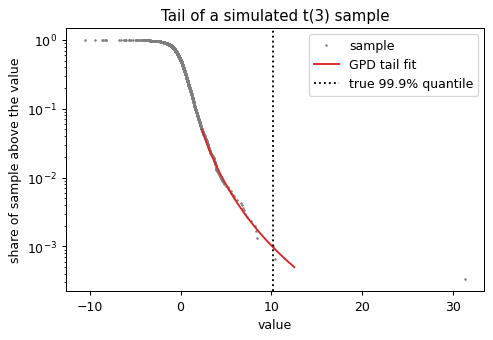

In [9]:
rng5 = np.random.default_rng(SEED + 5)
nu_df, n5, p_target = 3, 3000, 0.999
true_q999 = stats.t.ppf(p_target, nu_df)

def tail_quantile(sample, p=p_target, level=0.95):
    u = np.quantile(sample, level)
    exc = sample[sample > u] - u
    xi, _, sigma = stats.genpareto.fit(exc, floc=0)
    return u + sigma / xi * ((len(sample) / len(exc) * (1 - p)) ** (-xi) - 1), xi, sigma, u, len(exc)

x5 = rng5.standard_t(nu_df, n5)      # simulated heavy-tailed sample
q_gpd, xi_hat, sigma_hat, u5, n_exc = tail_quantile(x5)
q_emp = np.quantile(x5, p_target)
print(f"threshold u (empirical 95% quantile): {u5:.3f}   exceedances: {n_exc}")
print(f"GPD fit: shape xi = {xi_hat:.3f} (true 1/3), scale sigma = {sigma_hat:.3f}")
print(f"true 99.9% quantile     : {true_q999:.3f}")
print(f"empirical 99.9% quantile: {q_emp:.3f}   (values above it: {(x5 > q_emp).sum()})")
print(f"GPD tail-formula 99.9%  : {q_gpd:.3f}")

# repeat the experiment 300 times with new simulated samples
err_emp, err_gpd = [], []
for r in range(300):
    s = rng5.standard_t(nu_df, n5)
    err_emp.append(abs(np.quantile(s, p_target) - true_q999))
    err_gpd.append(abs(tail_quantile(s)[0] - true_q999))
med_err_emp, med_err_gpd = float(np.median(err_emp)), float(np.median(err_gpd))
win_gpd = float(np.mean(np.array(err_gpd) < np.array(err_emp)))
print(f"over 300 repeats: median absolute error, empirical {med_err_emp:.3f}, GPD {med_err_gpd:.3f}; GPD closer in {win_gpd:.0%} of repeats")

fig, ax = plt.subplots()
srt = np.sort(x5)
ax.plot(srt, 1 - np.arange(1, n5 + 1) / (n5 + 1), ".", ms=2, color="#7f7f7f", label="sample")
pp = np.logspace(-1.3, -3.3, 60)
qq = u5 + sigma_hat / xi_hat * ((n5 / n_exc * pp) ** (-xi_hat) - 1)
ax.plot(qq, pp, color="#d62728", label="GPD tail fit")
ax.axvline(true_q999, color="black", ls=":", label="true 99.9% quantile")
ax.set_yscale("log")
ax.set_xlabel("value")
ax.set_ylabel("share of sample above the value")
ax.set_title("Tail of a simulated t(3) sample")
ax.legend()
plt.show()


On this one simulated sample the threshold is 2.320 with 150 exceedances. The fitted shape is 0.267 against a true value of 0.333. The true 99.9% quantile is 10.215. The empirical quantile is 8.462 and the tail formula gives 10.089.

One sample can mislead, so the cell repeats the experiment on 300 new simulated samples. The median absolute error is 1.524 for the empirical quantile and 1.243 for the GPD formula. The GPD is closer in 58% of the repeats. The advantage is real but modest at this sample size, and it grows as the target level moves further into the tail.

**How to splice.** Use the body model up to a splice level and the tail model above it.

1. Fit quantile regression (or boosting) for levels up to a splice level $\tau_0$, such as 0.95.
2. For each input, take the body model's $\tau_0$ prediction as the threshold $u$.
3. Fit a GPD to the exceedances of $y$ over that threshold, using the rows where $y > u$.
4. For a level $p > \tau_0$, report $u + (\sigma/\xi)\big[((1 - \tau_0)/(1 - p))^{\xi} - 1\big]$. This is the tail formula with $n_u / n = 1 - \tau_0$.
5. For a level $p \le \tau_0$, report the body model's prediction.

Check the fit of the exceedances before you trust the tail. The number of exceedances must be at least 50 or so. Fit with two or three thresholds and see whether $\xi$ changes a lot.

**Try it on your project.** Count how many rows lie above your 95% threshold. If the count is below 50, state that the tail estimate is weak and report the result for a lower level instead.


## 6. An implicit quantile network (IQN)

Linear and boosted models need one fit per $\tau$. An implicit quantile network takes $\tau$ as an input, so one fit gives every quantile. It is a neural network $G(\tau, x)$ that outputs the $\tau$ quantile of $y$ given features $x$.

**Say plainly what it needs.** A network has thousands of weights. It needs tens of thousands of rows to learn a whole quantile function. With a few hundred rows use Section 3 or Section 4. The cell after the fan plot shows the error with 300 rows.

**Read this as a template.** You meet PyTorch properly only in Lab 12 on 2 December. The code below is a template to adapt, and each line is explained under the code. You do not need to master it now.

The recipe:

1. Build a network with two branches. One branch turns the features $x$ into a vector. The other turns $\tau$ into a vector of the same size, through a cosine embedding $\cos(i\pi\tau)$ for $i = 1, \dots, m$.
2. Multiply the two vectors element by element. Pass the result through a small network that outputs one number, the predicted quantile.
3. At each training step, draw a fresh random $\tau$ for every row in the batch and minimize the pinball loss at that $\tau$.

The data are *simulated*: $x$ is uniform on $[0, 1]$ and $y = \sin(2\pi x) + (0.1 + 0.6x)\,\varepsilon$ with $\varepsilon$ standard normal. The center is a wave and the noise grows with $x$. The true quantile at level $\tau$ is $\sin(2\pi x) + (0.1 + 0.6x)\,z_\tau$, where $z_\tau$ is the standard normal quantile, so we can measure the error exactly.


In [10]:
import torch
import torch.nn as nn

torch.set_num_threads(4)

class IQN(nn.Module):
    def __init__(self, d, h=64, m=16):
        super().__init__()
        self.m = m
        self.x_net = nn.Sequential(nn.Linear(d, h), nn.ReLU())        # branch for the features
        self.tau_net = nn.Sequential(nn.Linear(m, h), nn.ReLU())      # branch for tau
        self.head = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 1))

    def forward(self, x, tau):                                        # x: (n, d), tau: (n, 1)
        freqs = torch.arange(1, self.m + 1) * np.pi                   # i * pi for i = 1..m
        tau_vec = self.tau_net(torch.cos(tau * freqs))                # cosine embedding of tau
        return self.head(self.x_net(x) * tau_vec).squeeze(-1)         # element-wise product

def pinball_torch(y, q, tau):
    u = y - q
    t = tau.squeeze(-1)
    return torch.maximum(t * u, (t - 1) * u).mean()

def fit_iqn(x, y, steps=3000, batch=512, seed=0):
    torch.manual_seed(seed)
    xm, xs, ym, ys = x.mean(0), x.std(0), y.mean(), y.std()           # standardize inputs and target
    xt = torch.tensor((x - xm) / xs, dtype=torch.float32)
    yt = torch.tensor((y - ym) / ys, dtype=torch.float32)
    net = IQN(x.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    for _ in range(steps):
        idx = torch.randint(0, len(xt), (batch,))                     # a random batch of rows
        tau = torch.rand(batch, 1)                                    # new tau for every row, every step
        loss = pinball_torch(yt[idx], net(xt[idx], tau), tau)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return net, (xm, xs, ym, ys)

def predict_own(net, st, x, taus):                                    # returns (len(taus), n)
    xm, xs, ym, ys = st
    xt = torch.tensor((x - xm) / xs, dtype=torch.float32)
    with torch.no_grad():
        out = [net(xt, torch.full((len(xt), 1), float(t))).numpy() for t in taus]
    return np.array(out) * ys + ym


What each part does.

- `IQN.__init__` builds three pieces: `x_net` for the features, `tau_net` for the embedded $\tau$, and `head` for the output. `h` is the width of the hidden layers and `m` is the number of cosine terms.
- `forward` computes `torch.cos(tau * freqs)`, which is $\cos(i\pi\tau)$ for $i = 1, \dots, m$. `tau_net` maps that to a vector of length `h`. The line `self.x_net(x) * tau_vec` is the element-wise product. Then `head` returns one number per row.
- `pinball_torch` is the pinball loss from Section 2 written with `torch.maximum`. It equals $\max(\tau u, (\tau - 1)u)$.
- `fit_iqn` standardizes $x$ and $y$ to mean 0 and standard deviation 1, which makes training stable. In each of the `steps` iterations it draws a batch of rows, draws a new random `tau` for each row with `torch.rand`, and takes one Adam step on the pinball loss. The learning rate decays on a cosine schedule.
- `predict_own` evaluates the network on a grid of $\tau$ values and undoes the standardization.

The next cell simulates the data, trains the network and plots the fan of quantile curves.


own IQN: trained on 20000 rows in 2.0 s
mean absolute error against the true quantile curves (19 levels, 101 x values): 0.0256
for scale: sd of the noise runs from 0.1 to 0.7; sd of y overall = 0.828


own IQN trained on 300 rows: mean absolute error 0.0650


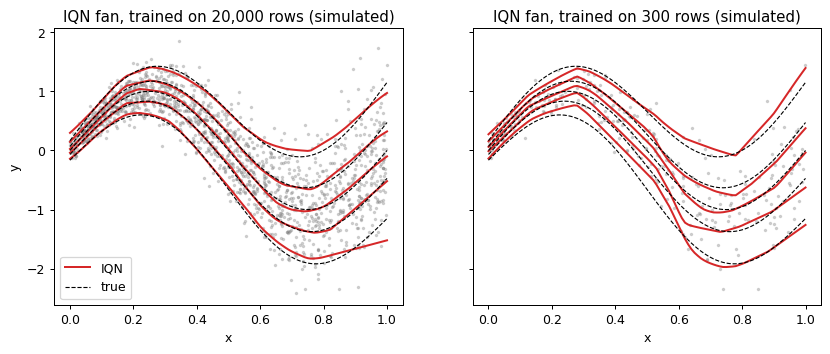

In [11]:
def simulate6(n, seed):
    r = np.random.default_rng(seed)
    x = r.uniform(0, 1, (n, 1))
    y = np.sin(2 * np.pi * x[:, 0]) + (0.1 + 0.6 * x[:, 0]) * r.normal(size=n)
    return x, y

def true_quantiles(x, taus):                                          # (len(taus), n)
    return np.sin(2 * np.pi * x[:, 0])[None, :] + (0.1 + 0.6 * x[:, 0])[None, :] * stats.norm.ppf(taus)[:, None]

x6, y6 = simulate6(20_000, SEED + 6)            # simulated training data
xte6, yte6 = simulate6(5_000, SEED + 66)        # simulated held-out data
xgrid = np.linspace(0, 1, 101)[:, None]
fan_taus = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
err_taus = np.round(np.arange(0.05, 0.951, 0.05), 2)

t0 = perf_counter()
net6, st6 = fit_iqn(x6, y6)
time_own = perf_counter() - t0

def quantile_error(pred_fun):
    return float(np.abs(pred_fun(xgrid, err_taus) - true_quantiles(xgrid, err_taus)).mean())

err_own = quantile_error(lambda x, t: predict_own(net6, st6, x, t))
print(f"own IQN: trained on {len(x6)} rows in {time_own:.1f} s")
print(f"mean absolute error against the true quantile curves (19 levels, 101 x values): {err_own:.4f}")
print(f"for scale: sd of the noise runs from 0.1 to 0.7; sd of y overall = {y6.std():.3f}")

# the same network trained on only 300 rows
x_small, y_small = x6[:300], y6[:300]
net_s, st_s = fit_iqn(x_small, y_small)
err_own_300 = quantile_error(lambda x, t: predict_own(net_s, st_s, x, t))
print(f"own IQN trained on 300 rows: mean absolute error {err_own_300:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (net, st, ttl) in zip(axes, [(net6, st6, "20,000 rows"), (net_s, st_s, "300 rows")]):
    xs_pts, ys_pts = (x6[:1500], y6[:1500]) if ttl.startswith("20") else (x_small, y_small)
    ax.scatter(xs_pts[:, 0], ys_pts, s=3, alpha=0.3, color="#7f7f7f")
    P = predict_own(net, st, xgrid, fan_taus)
    T = true_quantiles(xgrid, fan_taus)
    for k, t in enumerate(fan_taus):
        ax.plot(xgrid[:, 0], P[k], color="#d62728", lw=1.6, label="IQN" if k == 0 else None)
        ax.plot(xgrid[:, 0], T[k], color="black", ls="--", lw=0.9, label="true" if k == 0 else None)
    ax.set_title(f"IQN fan, trained on {ttl} (simulated)")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
plt.show()


The fan shows the quantile curves at $\tau$ = 0.05, 0.25, 0.5, 0.75 and 0.95, one curve per level. Red lines are the network and dashed black lines are the true curves. The fan widens to the right because the simulated noise grows with $x$.

Trained on 20,000 rows (2.0 seconds on CPU), the network has a mean absolute error of 0.0256 against the true curves. Trained on 300 rows the error is 0.0650. With 300 rows the error is 2.5 times larger. The 300-row fan is rougher, as the right panel shows, because the network has too little data to pin down a whole quantile function. That is why the table at the top sends small data sets to linear models.

**The same fit with the `gbc` package.** The `gbc` package (Polson and Sokolov) contains a tested IQN with the same idea plus a crossing penalty and standardization. `train_iqn(X, y, ...)` returns the model and the standardization constants. `sample_iqn(model, X_new, ...)` returns an array of shape (number of levels, number of rows) at evenly spaced levels from 0.005 to 0.995. Despite the name, these are fixed levels and not random draws. Pass `rearrange=True` to sort them.


gbc IQN: trained on 20000 rows in 30.3 s
mean absolute error against the true quantile curves: 0.0232   (own IQN: 0.0256)


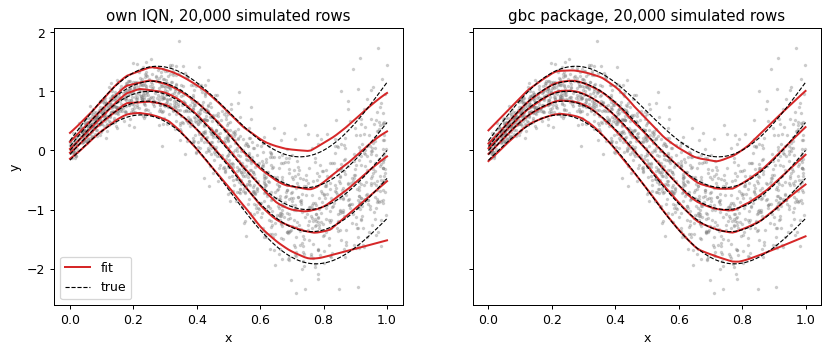

In [12]:
t0 = perf_counter()
model_g, xm_g, xs_g, ym_g, ys_g = train_iqn(x6, y6, epochs=800, hdim=64, nh=32, batch_size=2048, seed=SEED)
time_gbc6 = perf_counter() - t0

def gbc_predict(x, taus):
    return predict_iqn(model_g, x, xm_g, xs_g, ym_g, ys_g, taus=np.asarray(taus), rearrange=True)

err_gbc = quantile_error(gbc_predict)
print(f"gbc IQN: trained on {len(x6)} rows in {time_gbc6:.1f} s")
print(f"mean absolute error against the true quantile curves: {err_gbc:.4f}   (own IQN: {err_own:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (fun, ttl) in zip(axes, [(lambda x, t: predict_own(net6, st6, x, t), "own IQN"), (gbc_predict, "gbc package")]):
    ax.scatter(x6[:1500, 0], y6[:1500], s=3, alpha=0.3, color="#7f7f7f")
    P, T = fun(xgrid, fan_taus), true_quantiles(xgrid, fan_taus)
    for k in range(len(fan_taus)):
        ax.plot(xgrid[:, 0], P[k], color="#d62728", lw=1.6, label="fit" if k == 0 else None)
        ax.plot(xgrid[:, 0], T[k], color="black", ls="--", lw=0.9, label="true" if k == 0 else None)
    ax.set_title(f"{ttl}, 20,000 simulated rows")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
plt.show()


The `gbc` fit has a mean absolute error of 0.0232 and took 30.3 seconds. The own IQN has 0.0256. For scale, the noise standard deviation runs from 0.1 to 0.7. Both fits recover the wave in the center and the widening spread.

**Try it on your project.** Use an IQN only if you have tens of thousands of rows and you need many quantiles at once. Otherwise use Section 3 or Section 4. Always compare the IQN with boosting on held-out pinball loss.


## 7. Generative Bayesian Computation (GBC)

Generative Bayesian Computation (GBC) by Polson and Sokolov turns an IQN into a tool for Bayesian posteriors. It replaces Markov chain Monte Carlo (MCMC) with a network trained on simulations. You never evaluate a likelihood.

**The workflow.** Let $\theta$ be the unknown parameter and $y$ the data.

1. **Simulate.** Draw $\theta_i$ from the prior and then $y_i$ from the model given $\theta_i$, for $i = 1, \dots, N$. Each pair $(\theta_i, y_i)$ is one draw from the joint distribution.
2. **Summarize.** Reduce each data set to a short vector $S(y_i)$. The summary should keep what matters for $\theta$.
3. **Train.** Fit an IQN $G(\tau, S(y))$ by pinball loss to predict $\theta$ from $S(y)$. The network learns the posterior quantile function, because the conditional distribution of $\theta$ given $S(y)$ over simulated pairs *is* the posterior.
4. **Infer.** For observed data $y_\text{obs}$, evaluate $G(\tau, S(y_\text{obs}))$ on many levels $\tau$. These values are posterior quantiles. One forward pass gives them all.

**Why the sample size of your real data does not limit training.** The network trains on $N$ simulated pairs, and you choose $N$. A real data set with 8 observations can still use $N$ = 150,000 training simulations. **The answer is only as good as the simulator.** If the prior or the model is wrong, the posterior is wrong, however well the network is trained.

**Install.** The package is public on GitHub at `https://github.com/VadimSokolov/gbc`. This notebook uses tag `v0.7.2`. The setup cell installs it with `%pip install "git+https://github.com/VadimSokolov/gbc.git@v0.7.2"` if the import fails. On a laptop you can run the same command in a terminal without the leading `%`.

### 7a. Example one: Beta-binomial with an exact answer

Let $\theta$ be a success probability with prior Beta(2, 2). Observe $y$ successes in 20 trials, so $y \mid \theta \sim \text{Binomial}(20, \theta)$. The count $y$ is a sufficient summary: it holds everything the data say about $\theta$. The exact posterior is Beta$(2 + y,\ 2 + 20 - y)$. This lets us compare the network quantiles with the exact ones.

The data here are *simulated*, and the observed count $y_\text{obs} = 7$ is *made-up*.


trained on 20000 simulated pairs in 26.2 s;  observed count y = 7 of 20 (made-up)
      network  exact Beta  difference
tau                                  
0.05   0.2291      0.2216      0.0075
0.25   0.3086      0.3062      0.0024
0.50   0.3757      0.3715      0.0042
0.75   0.4429      0.4400      0.0029
0.95   0.5310      0.5405     -0.0095
largest quantile gap over the 199 levels, by observed count: {2: 0.0545, 7: 0.0559, 15: 0.0443}


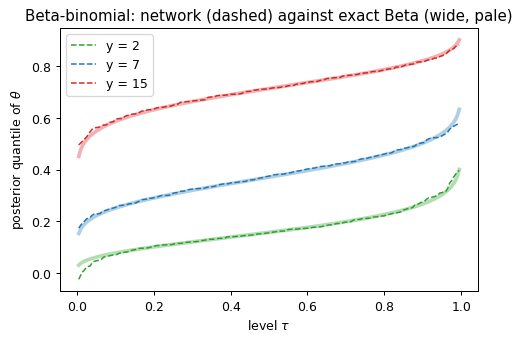

In [13]:
rng7 = np.random.default_rng(SEED + 7)
N_BB = 20_000
theta_bb = rng7.beta(2, 2, N_BB)                  # step 1: draw theta from the prior
y_bb = rng7.binomial(20, theta_bb)                # step 1: draw y given theta
S_bb = (y_bb / 20.0)[:, None]                     # step 2: summary = the count, scaled

t0 = perf_counter()                               # step 3: train the IQN
model_bb, xm_bb, xs_bb, ym_bb, ys_bb = train_iqn(S_bb, theta_bb, epochs=600, hdim=64, nh=32, batch_size=1024, seed=SEED)
time_bb = perf_counter() - t0

levels = np.linspace(0.005, 0.995, 199)
def bb_net_quantiles(y_obs, B=199, rearrange=True):    # step 4: one forward pass
    return sample_iqn(model_bb, np.array([[y_obs / 20.0]]), xm_bb, xs_bb, ym_bb, ys_bb, B=B, rearrange=rearrange)[:, 0]

def bb_exact(y_obs, taus):
    return stats.beta.ppf(taus, 2 + y_obs, 2 + 20 - y_obs)

y_obs_bb = 7
show = np.array([0.05, 0.25, 0.5, 0.75, 0.95])
qn = np.interp(show, levels, bb_net_quantiles(y_obs_bb))
qe = bb_exact(y_obs_bb, show)
tab_bb = pd.DataFrame({"tau": show, "network": qn, "exact Beta": qe, "difference": qn - qe}).set_index("tau")
print(f"trained on {N_BB} simulated pairs in {time_bb:.1f} s;  observed count y = {y_obs_bb} of 20 (made-up)")
print(tab_bb.round(4).to_string())

max_gap_bb = {y: float(np.abs(bb_net_quantiles(y) - bb_exact(y, levels)).max()) for y in (2, 7, 15)}
print("largest quantile gap over the 199 levels, by observed count:", {y: round(g, 4) for y, g in max_gap_bb.items()})

fig, ax = plt.subplots()
for y_o, color in [(2, "#2ca02c"), (7, "#1f77b4"), (15, "#d62728")]:
    ax.plot(levels, bb_exact(y_o, levels), color=color, lw=3, alpha=0.35)
    ax.plot(levels, bb_net_quantiles(y_o), color=color, lw=1.2, ls="--", label=f"y = {y_o}")
ax.set_xlabel(r"level $\tau$")
ax.set_ylabel(r"posterior quantile of $\theta$")
ax.set_title("Beta-binomial: network (dashed) against exact Beta (wide, pale)")
ax.legend()
plt.show()


For $y_\text{obs} = 7$ the network and the exact Beta quantiles are listed in the table above. The largest difference in the table is 0.0095. Over all 199 levels the largest gap is 0.0559 for $y = 7$, 0.0545 for $y = 2$ and 0.0443 for $y = 15$. Training took 26.2 seconds. The largest difference in the table is 3% of the width of the exact 90% interval (0.3188). The gap is larger for the counts at the edge of the prior's support. The simulation holds 633 pairs with a count of 2 and 1232 pairs with a count of 7, so there is less training signal at 2.

The one network answers all 21 possible counts. That is the sense in which GBC is *amortized*: you train once and then every new data set costs one forward pass.

### 7b. The utility identity

A decision maker with utility $U$ wants the expected utility $E[U(X)]$ of an uncertain amount $X$. With $Q_X(\tau)$ the quantile function of $X$,

$$E[U(X)] = \int_0^1 U\big(Q_X(\tau)\big)\,d\tau.$$

The right side averages the utility at every quantile level, each level weighted equally. With the quantile network you do not need a density. You average $U$ over the predicted quantiles. The next cell checks this with log utility, $U(x) = \log x$, in two cases.

1. $X$ has a Gamma distribution with shape 3 and scale 2 (made-up). The exact value is $\psi(3) + \log 2$, where $\psi$ is the digamma function.
2. $X$ is $\theta$ from the Beta-binomial posterior at $y_\text{obs} = 7$, using the network quantiles. The exact value is $\psi(a) - \psi(a + b)$ with $a = 9$ and $b = 15$.


In [14]:
from scipy.special import digamma

K = 1000
mid = (np.arange(K) + 0.5) / K                              # midpoints of K equal slices of (0, 1)
exact_gamma = digamma(3) + np.log(2)
quad_gamma = np.log(stats.gamma.ppf(mid, 3, scale=2)).mean()    # integral of U(Q(tau)) by the midpoint rule
mc_gamma = np.log(np.random.default_rng(SEED).gamma(3, 2, 1_000_000)).mean()
print(f"Gamma(3, scale 2), log utility: exact {exact_gamma:.4f}   quantile integral {quad_gamma:.4f}   Monte Carlo mean {mc_gamma:.4f}")

exact_beta = digamma(9) - digamma(24)
q_net_mid = predict_iqn(model_bb, np.array([[7 / 20.0]]), xm_bb, xs_bb, ym_bb, ys_bb, taus=mid, rearrange=True)[:, 0]
quad_beta = np.log(q_net_mid).mean()
print(f"Beta posterior (y = 7), log utility: exact {exact_beta:.4f}   integral of network quantiles {quad_beta:.4f}")


Gamma(3, scale 2), log utility: exact 1.6159   quantile integral 1.6160   Monte Carlo mean 1.6160


Beta posterior (y = 7), log utility: exact -1.0164   integral of network quantiles -1.0080


For the Gamma case the exact value is 1.6159, the quantile integral is 1.6160 and the Monte Carlo mean is 1.6160. For the Beta posterior the exact value is -1.0164 and the integral of the network quantiles is -1.0080. The Gamma case matches to three decimals because the quantiles are exact. The Beta case differs from exact by 0.0084. That difference is the network's quantile error showing up in the average. The identity itself is exact. The error comes from the quantile function you plug in.

### 7c. Example two: the eight schools

The eight schools data are a standard test case. Each school $j$ ran a coaching program and reported an estimated effect $y_j$ with a known standard error $\sigma_j$.

| School | A | B | C | D | E | F | G | H |
|---|---|---|---|---|---|---|---|---|
| $y_j$ | 28 | 8 | -3 | 7 | -1 | 1 | 18 | 12 |
| $\sigma_j$ | 15 | 10 | 16 | 11 | 9 | 11 | 10 | 18 |

The hierarchical model is $y_j \sim N(\theta_j, \sigma_j^2)$ and $\theta_j \sim N(\mu, \tau^2)$. Here $\theta_j$ is the true effect at school $j$, $\mu$ is the average true effect, and $\tau$ is the spread of true effects across schools. (This $\tau$ is a parameter. It is not a quantile level. The name clash is traditional. In this section the quantile level is called $\tau_q$.) The prior is

$$\mu \sim N(0, 30^2), \qquad \tau \sim \text{Uniform}(0, 30).$$

The uniform prior is **truncated at an upper limit of 30**, so $\tau$ cannot exceed 30. We need a proper prior to simulate from it. The limit matters: the data cannot rule out large $\tau$, so the posterior of $\tau$ depends on where we cut it off.

**Reference answers.** We use two. A short Gibbs sampler under the same prior, written in numpy, and an exact calculation of the posterior of $\tau$ on a grid. For $\tau$ the grid is the truth up to grid step, so it also checks the Gibbs sampler.

**The GBC fit.** We simulate $N$ = 150,000 data sets from the prior and the model, using the same $\sigma_j$. The summary $S(y)$ is the eight values $y_1, \dots, y_8$, plus the precision-weighted mean of the $y_j$ and Cochran's $Q = \sum_j (y_j - \bar y_w)^2/\sigma_j^2$, which help the network find the signal. We train one network for each target: $\mu$, $\tau$ and $\theta_A$.


In [15]:
y8 = np.array([28, 8, -3, 7, -1, 1, 18, 12.0])
s8 = np.array([15, 10, 16, 11, 9, 11, 10, 18.0])
MU_SD, TAU_MAX, J = 30.0, 30.0, 8
qlev = np.array([0.05, 0.25, 0.5, 0.75, 0.95])

# --- reference 1: exact posterior of tau on a grid (mu and theta integrated out) ---
tau_grid = np.linspace(0.0, TAU_MAX, 3001)[1:]
logp = np.array([
    stats.multivariate_normal(np.zeros(J), np.diag(s8**2 + t**2) + MU_SD**2 * np.ones((J, J))).logpdf(y8)
    for t in tau_grid
])
w_grid = np.exp(logp - logp.max())
cdf_grid = np.cumsum(w_grid) / w_grid.sum()
q_tau_grid = np.interp(qlev, cdf_grid, tau_grid)

# --- reference 2: Gibbs sampler under the same truncated prior ---
def gibbs(n_iter, seed):
    r = np.random.default_rng(seed)
    mu, tau = 0.0, 5.0
    out = np.empty((n_iter, 3))
    for i in range(n_iter):
        prec = 1 / s8**2 + 1 / tau**2
        theta = r.normal((y8 / s8**2 + mu / tau**2) / prec, 1 / np.sqrt(prec))
        pm = J / tau**2 + 1 / MU_SD**2
        mu = r.normal(theta.sum() / tau**2 / pm, 1 / np.sqrt(pm))
        ss = ((theta - mu) ** 2).sum()
        # 1/tau^2 given theta, mu is Gamma((J-1)/2, rate ss/2), cut to 1/tau^2 > 1/TAU_MAX^2
        lo = stats.gamma.cdf(1 / TAU_MAX**2, (J - 1) / 2, scale=2 / ss)
        tau = 1 / np.sqrt(stats.gamma.ppf(r.uniform(lo, 1), (J - 1) / 2, scale=2 / ss))
        out[i] = (mu, tau, theta[0])
    return out

t0 = perf_counter()
chain = gibbs(100_000, SEED)[5_000:]                # drop 5,000 burn-in iterations
time_gibbs = perf_counter() - t0
q_gibbs = {k: np.quantile(chain[:, i], qlev) for i, k in enumerate(["mu", "tau", "theta_A"])}
print(f"Gibbs: 100,000 iterations, 5,000 burn-in, {time_gibbs:.1f} s")
print("tau quantiles, grid :", q_tau_grid.round(2))
print("tau quantiles, Gibbs:", q_gibbs["tau"].round(2))


Gibbs: 100,000 iterations, 5,000 burn-in, 6.3 s
tau quantiles, grid : [ 0.48  2.44  5.17  8.98 16.59]
tau quantiles, Gibbs: [ 0.43  2.37  5.09  8.91 16.57]


trained {'mu': 81.0, 'tau': 84.9, 'theta_A': 84.6} seconds
 target  tau_q   GBC  Gibbs  grid
     mu   0.05 -0.53  -0.33   NaN
     mu   0.25  4.64   4.43   NaN
     mu   0.50  8.09   7.62   NaN
     mu   0.75 11.18  10.85   NaN
     mu   0.95 16.52  15.79   NaN
    tau   0.05  0.15   0.43  0.48
    tau   0.25  2.41   2.37  2.44
    tau   0.50  5.09   5.09  5.17
    tau   0.75  9.61   8.91  8.98
    tau   0.95 18.31  16.57 16.59
theta_A   0.05 -2.18  -0.10   NaN
theta_A   0.25  6.18   5.71   NaN
theta_A   0.50 11.46   9.90   NaN
theta_A   0.75 17.08  15.14   NaN
theta_A   0.95 27.79  26.31   NaN
largest quantile gap, GBC vs Gibbs: {'mu': 0.73, 'tau': 1.74, 'theta_A': 2.08}
largest tau-quantile gap, GBC vs grid: 1.72;  Gibbs vs grid: 0.08


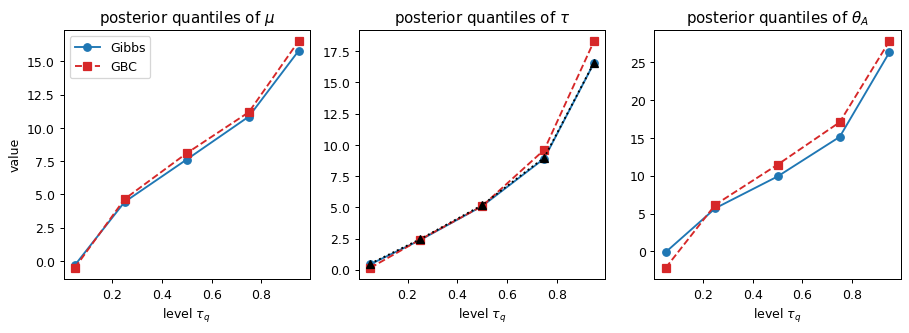

In [16]:
# --- GBC: simulate from the prior and the model ---
rng8 = np.random.default_rng(SEED + 8)
N8 = 150_000
mu_s = rng8.normal(0, MU_SD, N8)
tau_s = rng8.uniform(0, TAU_MAX, N8)
theta_s = rng8.normal(mu_s[:, None], tau_s[:, None], (N8, J))
y_s = rng8.normal(theta_s, s8)

def summary8(Y):
    w = 1 / s8**2
    wm = (Y * w).sum(1) / w.sum()
    Q = (((Y - wm[:, None]) / s8) ** 2).sum(1)
    return np.column_stack([Y, wm, Q])

S_s = summary8(y_s)
S_obs = summary8(y8[None, :])
targets = {"mu": mu_s, "tau": tau_s, "theta_A": theta_s[:, 0]}

q_gbc, time_gbc8 = {}, {}
for k, target in targets.items():
    t0 = perf_counter()
    m, xm, xs, ym, ys = train_iqn(S_s, target, epochs=200, hdim=128, nh=32, batch_size=2048, seed=SEED)
    time_gbc8[k] = perf_counter() - t0
    draws = sample_iqn(m, S_obs, xm, xs, ym, ys, B=199, rearrange=True)[:, 0]
    q_gbc[k] = np.interp(qlev, levels, draws)
    if k == "tau":
        q_gbc[k] = np.maximum(q_gbc[k], 0.0)         # tau is at least 0 by the prior, so clip

rows = []
for k in targets:
    for j, t in enumerate(qlev):
        rows.append({"target": k, "tau_q": t, "GBC": q_gbc[k][j], "Gibbs": q_gibbs[k][j],
                     "grid": q_tau_grid[j] if k == "tau" else np.nan})
tab8 = pd.DataFrame(rows)
print("trained", {k: round(v, 1) for k, v in time_gbc8.items()}, "seconds")
print(tab8.round(2).to_string(index=False))

gap8 = {k: float(np.abs(q_gbc[k] - q_gibbs[k]).max()) for k in targets}
gap8_tau_grid = float(np.abs(q_gbc["tau"] - q_tau_grid).max())
gibbs_vs_grid = float(np.abs(q_gibbs["tau"] - q_tau_grid).max())
print("largest quantile gap, GBC vs Gibbs:", {k: round(v, 2) for k, v in gap8.items()})
print(f"largest tau-quantile gap, GBC vs grid: {gap8_tau_grid:.2f};  Gibbs vs grid: {gibbs_vs_grid:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (k, lab) in zip(axes, [("mu", r"$\mu$"), ("tau", r"$\tau$"), ("theta_A", r"$\theta_A$")]):
    ax.plot(qlev, q_gibbs[k], "o-", color="#1f77b4", label="Gibbs")
    ax.plot(qlev, q_gbc[k], "s--", color="#d62728", label="GBC")
    if k == "tau":
        ax.plot(qlev, q_tau_grid, "^:", color="black", label="grid (exact)")
    ax.set_xlabel(r"level $\tau_q$")
    ax.set_title(f"posterior quantiles of {lab}")
axes[0].set_ylabel("value")
axes[0].legend()
plt.show()


The table lists posterior quantiles at five levels for $\mu$, $\tau$ and $\theta_A$. The plot shows the same numbers. Training took 81, 85 and 85 seconds. The Gibbs run took 6 seconds. Gibbs and the exact grid for $\tau$ agree to within 0.08, so the Gibbs numbers are a reliable reference.

**How close is GBC here?** The largest gap between a GBC quantile and the Gibbs quantile at the same level is, for $\mu$ 0.73 (5% of the Gibbs 90% interval width of 16.1), $\tau$ 1.74 (11% of the Gibbs 90% interval width of 16.1), $\theta_A$ 2.08 (8% of the Gibbs 90% interval width of 26.4). Against the exact grid, the largest gap for $\tau$ is 1.72. GBC is close to Gibbs in the middle of the distribution and less accurate in the tails. The $\tau$ quantile at level 0.05 is clipped at 0 because the prior says $\tau \ge 0$. The network has no built-in knowledge of that bound. The hardest part is that the observed $y$ lies in a small corner of the simulated data: most simulated data sets have a much larger spread than the eight observed values, so few training examples resemble them. Treat the differences above as the honest size of the approximation error at this training budget.

**What to do when GBC is not close.**

- Simulate more data sets and train for more steps. Both cost only compute.
- Narrow the prior to the region the data support, simulate again, and retrain. Check that the answer does not change when you widen it again.
- Give the network a better summary $S(y)$, for example the posterior mean from a quick approximate fit.
- Compare against an exact or MCMC answer on a case where one exists, as done here, before you trust the network on a case where none does.

**Try it on your project.** Write the simulator first: prior, model, and the summary you will feed the network. Check on a small case with a known answer that the network reproduces it. Then run it on your real data.


## 8. Calibration: does the fit say what it claims?

A quantile model is **calibrated** if the outcome falls below the $\tau$ forecast a share $\tau$ of the time, for every $\tau$. Two checks on held-out data:

- **Coverage.** The central interval between levels $(1 - \alpha)/2$ and $(1 + \alpha)/2$ should contain a share $\alpha$ of the outcomes.
- **PIT histogram.** The probability integral transform (PIT) of an outcome $y$ is the share of the model's quantile levels whose forecast is at or below $y$. If the model is calibrated the PIT values are uniform on $[0, 1]$, so the histogram is flat. A U shape means intervals are too narrow. A hump means they are too wide.

The cell checks both fits from Section 6 on the 5,000 simulated held-out rows, using levels $0.005, 0.010, \dots, 0.995$.


held-out coverage of central intervals (5,000 simulated rows)
         own IQN  gbc IQN
nominal                  
0.50       0.513    0.506
0.80       0.787    0.797
0.90       0.886    0.876
0.95       0.943    0.934


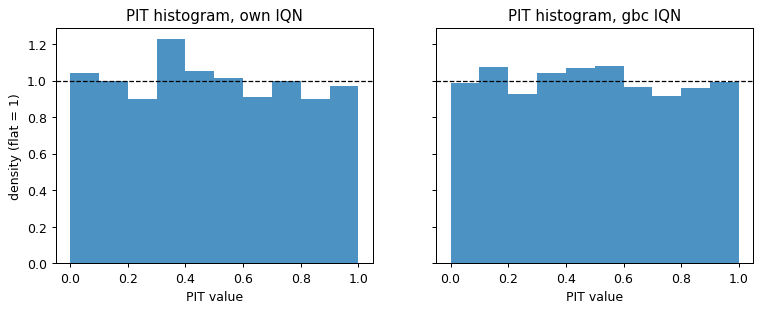

largest deviation of a PIT bin from flat: {'own': 0.228, 'gbc': 0.084}


In [17]:
Q_own = np.sort(predict_own(net6, st6, xte6, levels), axis=0)             # (199, n), sorted across levels
Q_gbc = sample_iqn(model_g, xte6, xm_g, xs_g, ym_g, ys_g, B=199, rearrange=True)

alphas = (0.5, 0.8, 0.9, 0.95)
cov_tab = pd.DataFrame({
    "nominal": alphas,
    "own IQN": [coverage(yte6, Q_own, a) for a in alphas],
    "gbc IQN": [coverage(yte6, Q_gbc, a) for a in alphas],
}).set_index("nominal")
print("held-out coverage of central intervals (5,000 simulated rows)")
print(cov_tab.round(3).to_string())

pit_own, pit_gbc = pit_values(yte6, Q_own), pit_values(yte6, Q_gbc)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, p, ttl in [(axes[0], pit_own, "own IQN"), (axes[1], pit_gbc, "gbc IQN")]:
    ax.hist(p, bins=10, range=(0, 1), density=True, color="#1f77b4", alpha=0.8)
    ax.axhline(1.0, color="black", ls="--", lw=1)
    ax.set_title(f"PIT histogram, {ttl}")
    ax.set_xlabel("PIT value")
axes[0].set_ylabel("density (flat = 1)")
plt.show()
pit_dev = {"own": float(np.abs(np.histogram(pit_own, bins=10, range=(0, 1), density=True)[0] - 1).max()),
           "gbc": float(np.abs(np.histogram(pit_gbc, bins=10, range=(0, 1), density=True)[0] - 1).max())}
print("largest deviation of a PIT bin from flat:", {k: round(v, 3) for k, v in pit_dev.items()})


Coverage of the central intervals on the held-out rows, nominal against observed: own IQN 0.5 -> 0.513, 0.8 -> 0.787, 0.9 -> 0.886, 0.95 -> 0.943; gbc IQN 0.5 -> 0.506, 0.8 -> 0.797, 0.9 -> 0.876, 0.95 -> 0.934. The largest miss is 0.014 for the own IQN and 0.024 for the gbc fit. In the PIT histograms a flat histogram has every bar at 1. The largest bar deviates from 1 by 0.228 for the own IQN and 0.084 for the gbc fit. With 5,000 rows, chance alone moves a bar by about 0.04, so a deviation above about 0.1 is a real departure from flat.

### Three failure modes and their fixes

**1. High signal-to-noise collapse.** The network merges the $\tau$ branch and the feature branch by multiplication. When $y$ is almost a deterministic function of $x$ (little noise), the network can confuse the signal with the noise. Symptoms: the training loss stops falling early and the PIT histogram is not flat. *Fix:* drop $\tau$ and fit a heteroskedastic network that predicts a mean and a variance (the `gbc.ensemble` module does this with an ensemble), or recalibrate the intervals on held-out data (the `gbc.conformal` module). For a project, a linear or boosted quantile model is also a sound fallback. This notebook does not demonstrate the collapse.

**2. Quantile crossing.** The network is only softly pushed to keep quantiles ordered, so predicted quantiles can cross. *Fix:* pass `rearrange=True` to `sample_iqn` and `predict_iqn`, which sorts the quantiles. The cell below measures how often the raw output of the Section 6 `gbc` fit crosses and how large the crossings are.

**3. Too few quantile levels.** If you evaluate on a coarse set of levels, tail summaries are coarse. *Fix:* use at least 200 levels, and more if you report intervals near 0 or 1. The cell below compares 20, 199 and 999 levels on the Beta-binomial posterior with $y_\text{obs} = 7$.


In [18]:
raw = sample_iqn(model_g, xte6, xm_g, xs_g, ym_g, ys_g, B=199, rearrange=False)
dips = np.diff(raw, axis=0)
frac_cross = float((dips < 0).mean())
max_dip = float(-dips.min() / y6.std())
srt = sample_iqn(model_g, xte6, xm_g, xs_g, ym_g, ys_g, B=199, rearrange=True)
frac_cross_sorted = float((np.diff(srt, axis=0) < 0).mean())
print(f"gbc fit, raw output: share of adjacent level pairs that cross = {frac_cross:.4f}; largest dip = {max_dip:.3f} sd of y")
print(f"after rearrange=True: share that cross = {frac_cross_sorted:.4f}")

exact95 = stats.beta.ppf([0.025, 0.975], 9, 15)
print(f"exact 95% interval: ({exact95[0]:.3f}, {exact95[1]:.3f})")
widths = {}
for B in (20, 199, 999):
    d = bb_net_quantiles(7, B=B)
    lo_, hi_ = np.quantile(d, [0.025, 0.975])
    widths[B] = (float(lo_), float(hi_))
    print(f"network 95% interval from B = {B:4d} levels: ({lo_:.3f}, {hi_:.3f})")


gbc fit, raw output: share of adjacent level pairs that cross = 0.3126; largest dip = 0.102 sd of y
after rearrange=True: share that cross = 0.0000
exact 95% interval: (0.197, 0.573)
network 95% interval from B =   20 levels: (0.201, 0.553)
network 95% interval from B =  199 levels: (0.213, 0.557)
network 95% interval from B =  999 levels: (0.213, 0.557)


For the Section 6 `gbc` fit, 0.3126 of adjacent level pairs cross in the raw output, and the largest dip is 0.102 of the standard deviation of $y$. After `rearrange=True` the share is 0.0000.

The exact 95% interval for the Beta posterior is (0.197, 0.573). From 20 levels the network gives (0.201, 0.553). From 199 levels it gives (0.213, 0.557) and from 999 levels (0.213, 0.557). The 20-level upper end is off from exact by 0.020, against 0.016 at 199 levels and 0.016 at 999 levels. Twenty levels are spaced 0.05 apart, so the 0.975 quantile is interpolated between two distant levels. The 199 and 999 level results agree with each other, so the small remaining gap to exact is network error and not level count.

**Try it on your project.** For every model you report, show held-out coverage at two or three nominal levels and one PIT histogram. If the histogram is not flat, say so and say which fix you tried.

## Summary

- A cost with two unequal sides gives a quantile: $\tau = c_\text{under}/(c_\text{under} + c_\text{over})$.
- Score quantile forecasts by pinball loss at that $\tau$, on held-out data, against a baseline.
- Few rows: linear quantile regression. A few thousand rows: add boosting. Tens of thousands of rows: an IQN is possible.
- Extreme highs: splice a generalized Pareto tail onto the body.
- With a simulator and no likelihood: GBC, checked against an exact answer on a small case.
- Always report coverage and look at a PIT histogram.
